## Using In Search of Lost Time by Proust to train a small language model

"In Search of Lost Time" by Marcel Proust is one of the longest books, containing around 7.6 million characters. This notebook attempts to train a small language model to write in the style of this book by training on the whole thing.

What this notebook does:
1. trains a SentencePiece BPE tokenizer with a 4,000-token vocabulary on the text in Search Lost Time. 
2. It then tokenizes the book and starts training a GPT-style language model using the first 90% of the tokens for training and the last 10% for validation. 
More clearly, the model is a decoder-only Transformer model in the style of Andrej Karpathy's nanoGPT tutorial (Hence the class names)
The model has around 1.8M parameters with a 256-token context window. It can be trained on a decently powerful laptop.

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import sentencepiece as spm
import matplotlib.pyplot as plt

In [2]:
device = 'mps' if torch.backends.mps.is_available() else 'cpu'
device

'mps'

In [3]:
# read isolt.txt
with open('isolt.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [4]:
print("length of dataset in characters: ", len(text))

length of dataset in characters:  7595898


In [5]:
# let's look at the first 1000 characters
print(text[:1000])

For a long time I used to go to bed early. Sometimes, when I had put out my 
candle, my eyes would close so quickly that I had not even time to say “I’m 
going to sleep.” And half an hour later the thought that it was time to go to sleep 
would awaken me; I would try to put away the book which, I imagined, was still 
in my hands, and to blow out the light; I had been thinking all the time, while I 
was asleep, of what I had just been reading, but my thoughts had run into a 
channel of their own, until I myself seemed actually to have become the subject 
of my book: a church, a quartet, the rivalry between Francois I and Charles V. 
This impression would persist for some moments after I was awake; it did not 
disturb my mind, but it lay like scales upon my eyes and prevented them from 
registering the fact that the candle was no longer burning. Then it would begin to 
seem unintelligible, as the thoughts of a former existence must be to a 
reincarnate spirit; the subject of my book woul

In [6]:
import os
# train the tokenizer only once; afterwards reuse the saved tok.model
# (delete tok.model / tok.vocab to force retraining)
if not os.path.exists('tok.model'):
    spm.SentencePieceTrainer.train(
        input='isolt.txt', model_prefix='tok', vocab_size=4000, model_type='bpe'
    )
enc = spm.SentencePieceProcessor()
enc.load('tok.model')
print(enc.encode(text[:1000]))
print(enc.decode(enc.encode(text[:1000])))

[691, 5, 305, 296, 47, 753, 15, 261, 15, 1101, 2705, 3962, 3023, 3956, 165, 47, 60, 855, 271, 91, 26, 263, 53, 3956, 91, 503, 130, 1438, 111, 3520, 44, 47, 60, 78, 255, 296, 15, 313, 108, 3964, 3965, 3952, 609, 15, 1262, 219, 246, 1441, 88, 785, 970, 9, 448, 44, 66, 59, 296, 15, 261, 15, 1262, 130, 1020, 713, 80, 3976, 47, 130, 2778, 15, 855, 865, 9, 1655, 72, 3956, 47, 1753, 3956, 59, 463, 27, 91, 1558, 3956, 50, 15, 509, 76, 271, 9, 854, 3976, 47, 60, 173, 1328, 152, 9, 296, 3956, 647, 47, 59, 2931, 3956, 20, 223, 47, 60, 449, 173, 2236, 3956, 160, 91, 2057, 60, 1895, 387, 5, 715, 3944, 258, 20, 215, 464, 3956, 962, 47, 382, 502, 1868, 15, 118, 993, 9, 1739, 20, 91, 1655, 3988, 5, 1995, 3956, 5, 272, 190, 93, 3956, 9, 1878, 1187, 422, 805, 722, 3953, 907, 47, 50, 467, 1120, 294, 3962, 929, 1285, 130, 374, 159, 79, 309, 1614, 353, 47, 59, 1020, 268, 3976, 66, 318, 78, 2219, 3960, 91, 547, 3956, 160, 66, 1761, 232, 499, 69, 31, 344, 91, 503, 50, 2676, 162, 131, 579, 1117, 25, 9, 831, 4

In [7]:
# here are all the unique tokens that occur in this text
tokens = sorted(list(set(enc.encode(text))))
# the model's vocab must cover every possible ID (0..3999), not just the IDs that occur in the text,
# otherwise IDs >= len(tokens) index past the embedding / output layer
token_size = enc.get_piece_size()
print("unique tokens used:", len(tokens), "| max ID:", max(tokens))
print(tokens)
for i, token in enumerate(tokens):
    print(f"{i}: {token} -> {enc.decode([token])}")
print(token_size)

unique tokens used: 3980 | max ID: 3999
[0, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 

In [8]:
# let's now encode the entire text dataset and store it into a torch.Tensor
data = torch.tensor(enc.encode(text), dtype=torch.long) # encode all the input text into a list of integers, then convert to a tensor
print(data.shape, data.dtype)
print(data[:5])

torch.Size([1904205]) torch.int64
tensor([691,   5, 305, 296,  47])


In [9]:
# Let's now split up the data into train and validation sets
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

## model

In [10]:
# hyperparameters
batch_size = 64 # how many independent sequences will we process in parallel?
block_size = 256 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 3e-4
device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.2

# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,hs)
        q = self.query(x) # (B,T,hs)
        # compute attention scores ("affinities"), scaled by sqrt(head_size)
        wei = q @ k.transpose(-2,-1) * k.shape[-1]**-0.5 # (B, T, hs) @ (B, hs, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,hs)
        out = wei @ v # (B, T, T) @ (B, T, hs) -> (B, T, hs)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(token_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.lm_head = nn.Linear(n_embd, token_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
        x = tok_emb + pos_emb # (B,T,C)
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,token_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
            if _ % 500 == 0:
                print(f"Generated {idx.shape[1]} tokens so far...")
        return idx

In [11]:

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

lossi = []

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    # sample a batch of data
    xb, yb = get_batch('train')
    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
      # track stats
    lossi.append(loss.log10().item())

print("ALL DONE!")

1.852576 M parameters
step 0: train loss 8.4617, val loss 8.4621
step 100: train loss 6.4906, val loss 6.6478
step 200: train loss 6.1391, val loss 6.3385
step 300: train loss 5.7700, val loss 6.0146
step 400: train loss 5.5489, val loss 5.8200
step 500: train loss 5.4127, val loss 5.6941
step 600: train loss 5.3110, val loss 5.6078
step 700: train loss 5.2228, val loss 5.5319
step 800: train loss 5.1457, val loss 5.4547
step 900: train loss 5.0754, val loss 5.3960
step 1000: train loss 5.0082, val loss 5.3469
step 1100: train loss 4.9496, val loss 5.2933
step 1200: train loss 4.9031, val loss 5.2514
step 1300: train loss 4.8568, val loss 5.2083
step 1400: train loss 4.8141, val loss 5.1700
step 1500: train loss 4.7801, val loss 5.1415
step 1600: train loss 4.7470, val loss 5.1146
step 1700: train loss 4.7223, val loss 5.0912
step 1800: train loss 4.6944, val loss 5.0704
step 1900: train loss 4.6710, val loss 5.0461
step 2000: train loss 4.6447, val loss 5.0274
step 2100: train loss 4.

Text(0, 0.5, 'log10(train loss)')

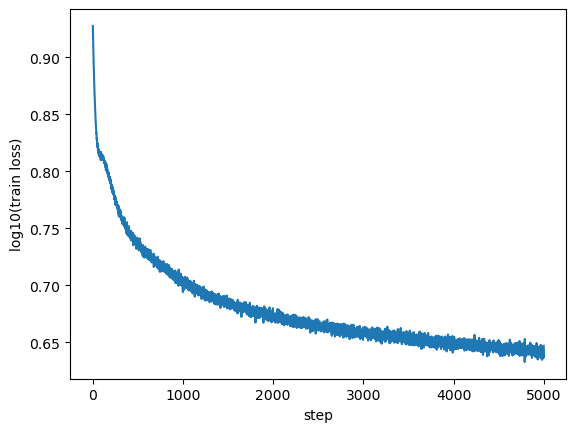

In [12]:
plt.plot(lossi)
plt.xlabel('step')
plt.ylabel('log10(train loss)')

In [13]:
# generate from the model
prompt = "For a long time"
context = torch.tensor([enc.encode(prompt)], dtype=torch.long, device=device)
print(enc.decode(m.generate(context, max_new_tokens=500)[0].tolist()))

Generated 5 tokens so far...
For a long time he set her capruding to face and thought, so much her advise. And Swann was,” discovered — merely a faint impression afterwards that fell back to which lay back: “Who would say M. Govern Esteh of a reward tact: ‘Sem Dieve’’ I’t you know, think nothing you was writing by that that he will be any lives; he can’s friend,” you always guise on?” elarlablaying, “I am not know, where I am the audacked my father had the Guermantes! I have thought to my dear, but it’ve ⁇ fafesemble; I’s wending a distinctless. But, he was simply because they’s got it is to be time, by a friend with vaging to Swann to it.” And Mme. “Yes! I think he was the fright, I doubt since I was said this I climo you one thing as well, my boy?” said Brichot. Meanwhile an answer was not to him the pink failing, if it was an attitude that he were to you.” “you see it do you, you really speak to begin about you to shan’s forgotten politics; it up the number of densisien before Tonn 